In [85]:
import pandas as pd
import matplotlib.pyplot as plt



In [5]:
df1=pd.read_csv("apollo_appointments_fact.csv")


In [6]:
df1.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,11/15/2023,Wednesday,2,11,Q4,2023,15,...,No,NaN,0,2700,2700,UPI,11.0,40.0,4.8,84.2
1,APPT5000002,PAT128732,DOC1049,3/13/2023,Monday,0,3,Q1,2023,9,...,No,NaN,0,1400,1400,UPI,21.0,18.0,4.1,64.5
2,APPT5000003,PAT137532,DOC1033,2/7/2022,Monday,0,2,Q1,2022,17,...,No,NaN,0,600,600,Net Banking,6.0,6.0,5.0,75.6
3,APPT5000004,PAT113284,DOC1288,11/20/2023,Monday,0,11,Q4,2023,17,...,No,NaN,0,1275,1275,UPI,2.0,25.0,4.4,68.6
4,APPT5000005,PAT107443,DOC1064,2/2/2024,Friday,4,2,Q1,2024,19,...,No,NaN,0,1700,1700,Cash,7.0,13.0,3.5,67.7


In [7]:
df1.shape

(75000, 52)

In [8]:
df1.columns

Index(['appointment_id', 'patient_id', 'doctor_id', 'appointment_date',
       'appointment_day', 'appointment_day_of_week', 'appointment_month',
       'appointment_quarter', 'appointment_year', 'appointment_hour',
       'appointment_minute', 'time_slot', 'time_of_day', 'booking_date',
       'booking_lead_days', 'booking_channel', 'appointment_type', 'specialty',
       'city', 'state', 'hospital_name', 'patient_age', 'age_group',
       'patient_gender', 'patient_city_tier', 'patient_chronic_condition',
       'apollo_member', 'membership_type', 'reminder_type', 'reminders_sent',
       'patient_prior_visits', 'patient_prior_no_shows', 'is_first_visit',
       'repeat_visit', 'visit_reason', 'appointment_status', 'no_show',
       'no_show_flag', 'cancellation_reason', 'consultation_fee',
       'discount_pct', 'actual_fee_charged', 'insurance_coverage',
       'insurance_provider', 'insurance_covered_amount',
       'patient_out_of_pocket', 'revenue_realized', 'payment_mode',
    

In [9]:
df1.columns.tolist()

['appointment_id',
 'patient_id',
 'doctor_id',
 'appointment_date',
 'appointment_day',
 'appointment_day_of_week',
 'appointment_month',
 'appointment_quarter',
 'appointment_year',
 'appointment_hour',
 'appointment_minute',
 'time_slot',
 'time_of_day',
 'booking_date',
 'booking_lead_days',
 'booking_channel',
 'appointment_type',
 'specialty',
 'city',
 'state',
 'hospital_name',
 'patient_age',
 'age_group',
 'patient_gender',
 'patient_city_tier',
 'patient_chronic_condition',
 'apollo_member',
 'membership_type',
 'reminder_type',
 'reminders_sent',
 'patient_prior_visits',
 'patient_prior_no_shows',
 'is_first_visit',
 'repeat_visit',
 'visit_reason',
 'appointment_status',
 'no_show',
 'no_show_flag',
 'cancellation_reason',
 'consultation_fee',
 'discount_pct',
 'actual_fee_charged',
 'insurance_coverage',
 'insurance_provider',
 'insurance_covered_amount',
 'patient_out_of_pocket',
 'revenue_realized',
 'payment_mode',
 'wait_time_minutes',
 'consultation_duration_min',
 '

In [10]:
df1['appointment_year'].value_counts().sort_index()

appointment_year
2022    24868
2023    25054
2024    25078
Name: count, dtype: int64

In [11]:
# monthly appointment volume
monthly_volume = df1.groupby(['appointment_year','appointment_month']).size().reset_index(name ='appointment_count')

In [12]:
monthly_volume

,appointment_year,appointment_month,appointment_count
0,2022,1,2426
1,2022,2,2012
2,2022,3,2085
3,2022,4,1926
4,2022,5,2033
5,2022,6,1823
6,2022,7,1833
7,2022,8,1835
8,2022,9,2115
9,2022,10,2206


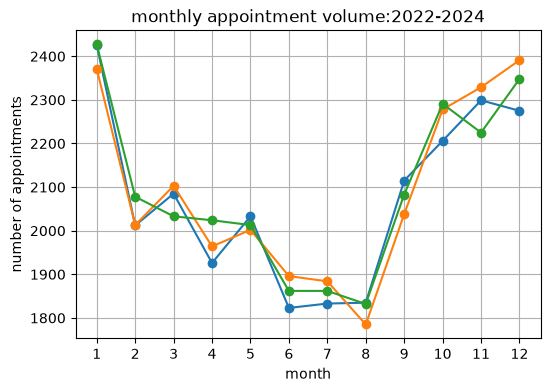

In [13]:

plt.figure(figsize=(6,4))
for year in sorted(monthly_volume['appointment_year'].unique()):
    data= monthly_volume[monthly_volume['appointment_year']==year]
    plt.plot(data['appointment_month'] , 
            data['appointment_count'],
            marker='o',
            label=str(year) )
plt.title('monthly appointment volume:2022-2024')
plt.xlabel('month')
plt.ylabel('number of appointments')
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

In [14]:
# Appointment status
df1['appointment_status'].value_counts()

appointment_status
Completed    55275
No-Show      11584
Cancelled     5793
Scheduled     2348
Name: count, dtype: int64

In [15]:
# Booking channel volume
channel_count = df1['booking_channel'].value_counts()

In [16]:
channel_count

booking_channel
Apollo App     34042
Website        18545
Call Centre    11201
Walk-In         7501
Partner App     3711
Name: count, dtype: int64

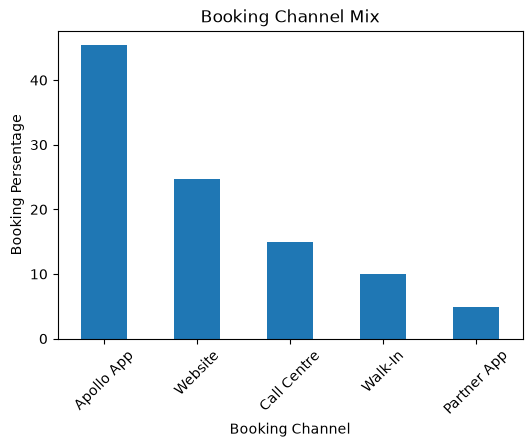

In [17]:
#channel mix looks
channel_mix = df1['booking_channel'].value_counts(normalize=True)*100
channel_mix.plot(kind='bar',figsize=(6,4))
plt.title('Booking Channel Mix')
plt.xlabel('Booking Channel')
plt.ylabel('Booking Persentage')
plt.xticks(rotation=45)

plt.show()

In [18]:
df2=pd.read_csv("apollo_doctors_dim.csv")

In [19]:
df2.head()

,doctor_id,doctor_name,specialty,qualification,experience_years,city,state,hospital_name,consultation_fee,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,DOC1001,Dr. Deepa Sharma,Urology,"MBBS, MCh",12,Bengaluru,Karnataka,Apollo Hospital Bannerghatta,2300,4.4,1502,Mon-Fri,15,Yes,No
1,DOC1002,Dr. Venkatesan Khan,Paediatrics,"MBBS, MS, FRCS",25,Chandigarh,Punjab,Apollo Clinic Sector 8,1200,4.5,2453,Mon-Sat,10,Yes,Yes
2,DOC1003,Dr. Pradeep Menon,General Physician,"MBBS, DM",13,Mumbai,Maharashtra,Apollo Clinic Andheri,700,4.7,995,Mon-Wed-Fri-Sat,15,No,No
3,DOC1004,Dr. Vivek Mathew,General Physician,"MBBS, MD",31,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,1000,4.9,666,Mon-Wed-Fri-Sat,20,Yes,Yes
4,DOC1005,Dr. Savita Philip,General Physician,"MBBS, MD, PhD",5,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,600,4.5,1383,Mon-Sat,30,Yes,Yes


In [20]:
df2.columns.tolist()

['doctor_id',
 'doctor_name',
 'specialty',
 'qualification',
 'experience_years',
 'city',
 'state',
 'hospital_name',
 'consultation_fee',
 'rating',
 'total_reviews',
 'available_days',
 'avg_slot_duration_min',
 'accepts_insurance',
 'teleconsult_enabled']

In [21]:
#Specialty no show rate
speciality_rate = df1.groupby("specialty")["no_show_flag"].mean() * 100

print(speciality_rate)

specialty
Cardiology           13.553114
Dermatology          20.552147
ENT                  18.347261
Endocrinology        17.010062
Gastroenterology     14.383823
General Physician    15.040450
Gynaecology          13.834184
Neurology            10.314440
Ophthalmology        15.753210
Orthopaedics         14.492754
Paediatrics          11.845816
Psychiatry           23.787220
Pulmonology          15.015244
Urology              13.992129
Name: no_show_flag, dtype: float64


In [22]:
#City no-show rate
city_rate = df1.groupby("city")["no_show_flag"].mean() * 100
print(city_rate)

city
Ahmedabad     15.648536
Bengaluru     14.918280
Bhopal        16.169394
Chandigarh    14.607646
Chennai       14.580009
Coimbatore    13.654618
Delhi         16.305661
Hyderabad     15.593494
Indore        13.650651
Jaipur        15.679825
Kochi         15.778098
Kolkata       15.888965
Lucknow       16.645161
Mumbai        16.518968
Pune          12.871287
Name: no_show_flag, dtype: float64


In [23]:
# Highest and Lowest show rate
print("Highest specialty:", speciality_rate.idxmax())
print("Lowest specialty:", speciality_rate.idxmin())

print("Highest city:", city_rate.idxmax())
print("Lowest city:", city_rate.idxmin())

Highest specialty: Psychiatry
Lowest specialty: Neurology
Highest city: Lucknow
Lowest city: Pune


In [67]:
#How does booking lead time affect the probability of a no-show
lead_time = df1.groupby("booking_lead_days")["no_show_flag"].mean() * 100
print(lead_time)

booking_lead_days
0     15.343585
1     12.817659
2     14.141176
3     15.199430
4     16.143498
5     15.685403
6     14.182344
7     18.103744
8     18.079096
9     18.082789
10    17.105263
11    19.768404
12    16.353591
13    16.897507
14    23.491028
15    18.871595
16    19.899244
17    19.333333
18    17.117117
19    20.873786
20    19.463087
21    14.406780
22    21.904762
23    20.224719
24    17.187500
25    24.444444
26    15.384615
27    27.500000
28    22.222222
29    19.047619
30    22.471910
Name: no_show_flag, dtype: float64


<Axes: xlabel='booking_lead_days'>

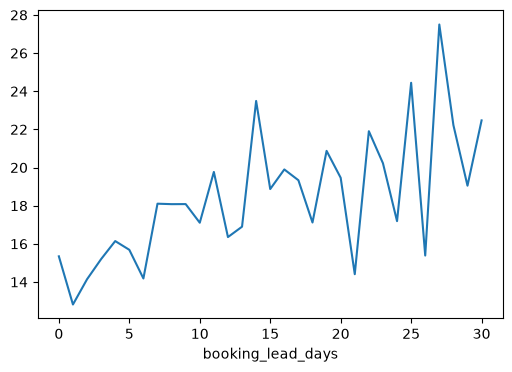

In [68]:
#line chart
lead_time.plot(kind="line",figsize=(6,4))

In [26]:
#Do evening slots, weekends, and longer-lead bookings see higher dropout?


In [27]:
#to create new column
df1['No_Show'] = df1['appointment_status'] == 'No-Show'

In [28]:
df1.groupby('time_of_day')['No_Show'].mean() * 100

time_of_day
Afternoon    17.217050
Evening      17.766700
Morning      13.296484
Name: No_Show, dtype: float64

In [29]:
#weekend column
df1['Weekend'] = df1['appointment_day_of_week'] >= 5

In [30]:
df1.groupby('Weekend')['no_show_flag'].mean() * 100

Weekend
False    14.383420
True     18.064993
Name: no_show_flag, dtype: float64

In [31]:
#Booking lead days
df1.groupby('booking_lead_days')['no_show_flag'].mean() * 100

booking_lead_days
0     15.343585
1     12.817659
2     14.141176
3     15.199430
4     16.143498
5     15.685403
6     14.182344
7     18.103744
8     18.079096
9     18.082789
10    17.105263
11    19.768404
12    16.353591
13    16.897507
14    23.491028
15    18.871595
16    19.899244
17    19.333333
18    17.117117
19    20.873786
20    19.463087
21    14.406780
22    21.904762
23    20.224719
24    17.187500
25    24.444444
26    15.384615
27    27.500000
28    22.222222
29    19.047619
30    22.471910
Name: no_show_flag, dtype: float64

In [32]:
#Which appointment types and booking channels carry the most no-show risk?


In [33]:
df1.groupby(['appointment_type', 'booking_channel'])['no_show_flag'].mean() * 100

appointment_type  booking_channel
Home Visit        Apollo App         24.605367
                  Call Centre        24.489796
                  Partner App        27.134725
                  Website            27.020292
In-Clinic         Apollo App          9.189987
                  Call Centre         9.835827
                  Partner App        13.583938
                  Walk-In            20.263965
                  Website            11.875000
Video Consult     Apollo App         18.776689
                  Call Centre        21.304676
                  Partner App        22.538553
                  Website            22.440585
Name: no_show_flag, dtype: float64

In [34]:
#How much does reminder type reduce no-show rates compared to no-reminder patients?

In [35]:
df1.groupby('reminder_type')['no_show_flag'].mean() * 100

reminder_type
No Reminder              29.246533
SMS + WhatsApp           13.079959
SMS + WhatsApp + Call    11.049137
SMS Only                 15.765946
Name: no_show_flag, dtype: float64

In [36]:
df1.groupby(df1['reminders_sent'] == 0)['no_show_flag'].mean() * 100

reminders_sent
False    12.991724
True     29.246533
Name: no_show_flag, dtype: float64

In [37]:
#Does prior no-show history predict future no-show behaviour

In [38]:
df1.groupby('patient_prior_no_shows')['no_show_flag'].mean() * 100

patient_prior_no_shows
0    14.681960
1    19.615209
2    25.661117
3    29.927007
4    50.000000
5    50.000000
6     0.000000
Name: no_show_flag, dtype: float64

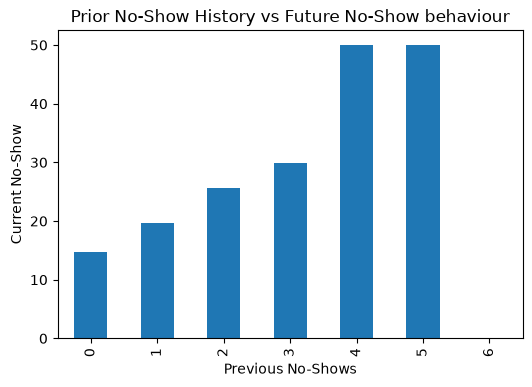

In [39]:
df1.groupby('patient_prior_no_shows')['no_show_flag'].mean().mul(100).plot(kind='bar',figsize=(6,4))

plt.xlabel('Previous No-Shows')
plt.ylabel('Current No-Show')
plt.title('Prior No-Show History vs Future No-Show behaviour')
plt.show()

In [40]:
#Do Apollo members and repeat patients show better attendance than non-members and first-time patients? 

In [41]:
#Apollo members vs non-members
df1.groupby('apollo_member')['no_show_flag'].mean() * 100

apollo_member
No     16.367540
Yes    12.244411
Name: no_show_flag, dtype: float64

In [42]:
#Repeat patients vs first-time patients
df1.groupby('repeat_visit')['no_show_flag'].mean() * 100

repeat_visit
No     58.696276
Yes     8.445773
Name: no_show_flag, dtype: float64

In [43]:
#How do age group, gender, and chronic condition status influence no-show likelihood? 

In [44]:
#Age group
df1.groupby('age_group')['no_show_flag'].mean() * 100

age_group
Adult (31-45)          17.476163
Child (0-12)           13.107997
Middle-aged (46-60)    16.222729
Senior (60+)           13.602352
Teen (13-18)           14.264013
Young Adult (19-30)    17.384154
Name: no_show_flag, dtype: float64

In [45]:
#Gender
df1.groupby('patient_gender')['no_show_flag'].mean() * 100

patient_gender
Female    15.543868
Male      15.339795
Name: no_show_flag, dtype: float64

In [46]:
#chronic condition
df1.groupby('patient_chronic_condition')['no_show_flag'].mean() * 100

patient_chronic_condition
Asthma            16.190882
Diabetes          15.307551
Heart Disease     15.817893
Hypertension      15.084096
Hypothyroidism    15.002116
Name: no_show_flag, dtype: float64

In [47]:
#Which visit reasons are most common and are some associated with higher dropout? 

In [48]:
#visit reason
df1['visit_reason'].value_counts()

visit_reason
Follow-up                       8807
Routine Checkup                 8637
Chronic Condition Management    8380
Digestive Problem               8245
Fever & Infection               7041
Joint Pain                      6664
Respiratory Issue               6590
Injury                          6087
Eye Care                        2959
Skin Issue                      2862
Mental Health                   2830
Cardiac Concern                 2708
Women's Health                  2449
Child Health                     741
Name: count, dtype: int64

In [49]:
# no show rate
df1.groupby('visit_reason')['no_show_flag'].mean() * 100

visit_reason
Cardiac Concern                 15.878877
Child Health                    14.170040
Chronic Condition Management    15.107399
Digestive Problem               15.730746
Eye Care                        15.005069
Fever & Infection               15.551768
Follow-up                       14.738276
Injury                          15.590603
Joint Pain                      16.236495
Mental Health                   15.724382
Respiratory Issue               15.477997
Routine Checkup                 15.155725
Skin Issue                      16.317261
Women's Health                  15.394038
Name: no_show_flag, dtype: float64

In [50]:
#What does the patient age distribution look like within specialties like Paediatrics, Gynaecology, and Psychiatry

In [51]:
# merge data frames
df = df1.merge(df2[['doctor_id', 'specialty']], on='doctor_id', how='left')

In [52]:
df.columns

Index(['appointment_id', 'patient_id', 'doctor_id', 'appointment_date',
       'appointment_day', 'appointment_day_of_week', 'appointment_month',
       'appointment_quarter', 'appointment_year', 'appointment_hour',
       'appointment_minute', 'time_slot', 'time_of_day', 'booking_date',
       'booking_lead_days', 'booking_channel', 'appointment_type',
       'specialty_x', 'city', 'state', 'hospital_name', 'patient_age',
       'age_group', 'patient_gender', 'patient_city_tier',
       'patient_chronic_condition', 'apollo_member', 'membership_type',
       'reminder_type', 'reminders_sent', 'patient_prior_visits',
       'patient_prior_no_shows', 'is_first_visit', 'repeat_visit',
       'visit_reason', 'appointment_status', 'no_show', 'no_show_flag',
       'cancellation_reason', 'consultation_fee', 'discount_pct',
       'actual_fee_charged', 'insurance_coverage', 'insurance_provider',
       'insurance_covered_amount', 'patient_out_of_pocket', 'revenue_realized',
       'payment_mo

In [53]:
result = df[
    df['specialty_y'].isin(['Paediatrics', 'Gynaecology', 'Psychiatry'])
].groupby(['specialty_y', 'age_group']).size()

result


specialty_y  age_group          
Gynaecology  Adult (31-45)           970
             Child (0-12)            480
             Middle-aged (46-60)     890
             Senior (60+)            918
             Teen (13-18)            252
             Young Adult (19-30)     603
Paediatrics  Child (0-12)           4354
             Teen (13-18)           2028
Psychiatry   Adult (31-45)           668
             Child (0-12)            327
             Middle-aged (46-60)     668
             Senior (60+)            683
             Teen (13-18)            213
             Young Adult (19-30)     430
dtype: int64

In [54]:
#How much revenue is being lost to no-shows? 

In [55]:
no_show = df1[df1['no_show_flag'] == 1]

In [56]:
lost_revenue = no_show['consultation_fee'].sum()

In [57]:
print("Revenue lost to no-shows:", lost_revenue)

Revenue lost to no-shows: 19725460


In [58]:
#How does average revenue vary across specialties and appointment types? 

In [59]:
#Average revenue by specialty
df.groupby('specialty_y')['actual_fee_charged'].mean()

specialty_y
Cardiology           1720.164620
Dermatology          1039.217791
ENT                  1008.504735
Endocrinology        1525.199329
Gastroenterology     1654.886303
General Physician     547.027674
Gynaecology          1336.096280
Neurology            1886.302824
Ophthalmology        1234.262762
Orthopaedics         1354.852031
Paediatrics           860.979003
Psychiatry           2024.347273
Pulmonology          1570.889863
Urology              1758.073459
Name: actual_fee_charged, dtype: float64

In [60]:
#Average revenue by appointment type
df.groupby('appointment_type')['actual_fee_charged'].mean()

appointment_type
Home Visit       1457.056703
In-Clinic        1175.533536
Video Consult     876.795175
Name: actual_fee_charged, dtype: float64

In [61]:
# compare speciality and appointment type
result = df.groupby(
    ['specialty_y', 'appointment_type']
)['actual_fee_charged'].mean().reset_index()

result

,specialty_y,appointment_type,actual_fee_charged
0,Cardiology,Home Visit,2161.815152
1,Cardiology,In-Clinic,1751.149835
2,Cardiology,Video Consult,1314.933754
3,Dermatology,Home Visit,1343.771599
4,Dermatology,In-Clinic,1063.184729
5,Dermatology,Video Consult,800.282998
6,ENT,Home Visit,1281.810627
7,ENT,In-Clinic,1031.168183
8,ENT,Video Consult,732.326172
9,Endocrinology,Home Visit,1960.433447


In [62]:
#Which cities generate the most revenue and what is the payment mode mix? 

In [76]:
#cities revenue
city_revenue = df.groupby("city")["revenue_realized"].sum().sort_values(ascending=False)
print(city_revenue)

city
Bengaluru     9990616
Delhi         9958247
Mumbai        8989613
Hyderabad     7503245
Chennai       7188473
Kolkata       6543084
Pune          4734139
Ahmedabad     3956890
Lucknow       3177444
Indore        2223207
Chandigarh    2221091
Jaipur        2199116
Coimbatore    1792804
Kochi         1731448
Bhopal        1684381
Name: revenue_realized, dtype: int64


In [78]:
# Payment mode
payment_mix = df["payment_mode"].value_counts()
print(payment_mix)

payment_mode
Pending        19725
Insurance      11641
Debit Card      7353
Net Banking     7349
Apollo Pay      7324
UPI             7259
Credit Card     7213
Cash            7136
Name: count, dtype: int64


<Axes: xlabel='city'>

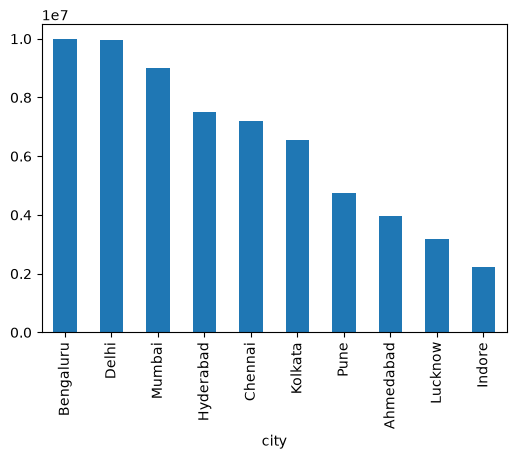

In [87]:
city_revenue.head(10).plot(kind="bar",figsize=(6,4))


In [88]:
# How does insurance coverage affect what patients pay out of pocket?

In [89]:
out_of_pocket = df.groupby('insurance_coverage')['patient_out_of_pocket'].mean()
print(out_of_pocket)

insurance_coverage
No     1138.408914
Yes     649.356182
Name: patient_out_of_pocket, dtype: float64


In [90]:
print(out_of_pocket.round(2))

insurance_coverage
No     1138.41
Yes     649.36
Name: patient_out_of_pocket, dtype: float64


TypeError: 'str' object is not callable

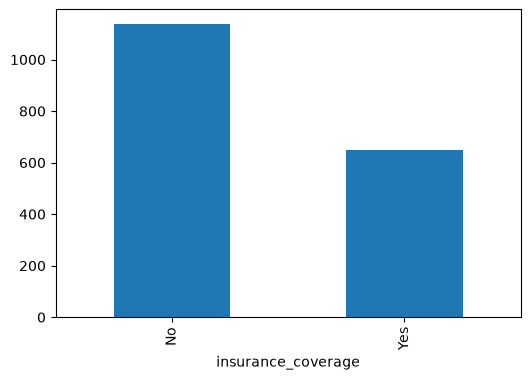

In [95]:

out_of_pocket.plot(kind="bar", figsize=(6,4))

plt.xlabel("Insurance Coverage")
plt.ylabel("Average Out-of-Pocket Payment")
plt.title("Insurance Coverage vs Out-of-Pocket Payment")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#Which specialties have the highest and lowest doctor utilisation rates? 

In [99]:
utilisation = df.groupby('specialty_x')['doctor_utilization_pct'].mean().sort_values(ascending=False)
print(utilisation)
print("Highest utilisation:")
print(utilisation.head(1))

print("\nLowest utilisation:")
print(utilisation.tail(1))

specialty_x
Gastroenterology     77.256288
Endocrinology        77.146277
Cardiology           76.814200
Gynaecology          76.804531
Paediatrics          76.664143
Neurology            76.632342
General Physician    76.590615
Urology              76.442568
Orthopaedics         76.430485
Dermatology          76.420516
Pulmonology          76.354615
ENT                  76.327542
Ophthalmology        76.193401
Psychiatry           76.181052
Name: doctor_utilization_pct, dtype: float64
Highest utilisation:
specialty_x
Gastroenterology    77.256288
Name: doctor_utilization_pct, dtype: float64

Lowest utilisation:
specialty_x
Psychiatry    76.181052
Name: doctor_utilization_pct, dtype: float64


In [101]:
#How long are patients waiting and does it vary by specialty or time of day? 

In [102]:
avg_wait = df["wait_time_minutes"].mean()

print("Average waiting time:", round(avg_wait, 2), "minutes")

Average waiting time: 11.55 minutes


In [103]:
# Average waiting time
wait_by_specialty = df.groupby("specialty_x")["wait_time_minutes"].mean().sort_values(ascending=False)

print(wait_by_specialty)

specialty_x
Ophthalmology        12.017454
Urology              11.905147
Dermatology          11.771648
Orthopaedics         11.701838
Neurology            11.638112
Gynaecology          11.616784
Cardiology           11.594240
General Physician    11.531807
Endocrinology        11.459441
Gastroenterology     11.390467
Pulmonology          11.385518
Psychiatry           11.338611
ENT                  11.298049
Paediatrics          11.175510
Name: wait_time_minutes, dtype: float64


In [104]:
# waiting time by specialty
wait_by_hour = df.groupby("appointment_hour")["wait_time_minutes"].mean()

print(wait_by_hour)

appointment_hour
8     11.576431
9     11.336831
10    11.730129
11    11.497774
12    11.709624
14    11.382312
15    11.419141
16    11.705161
17    11.517833
18    11.592540
19    11.541607
Name: wait_time_minutes, dtype: float64


In [109]:
#Is there a relationship between consultation duration and patient satisfaction? 

In [113]:
correlation = df["consultation_duration_min"].corr(
    df["patient_satisfaction_score"]
)

print("Correlation:", round(correlation, 2))

Correlation: -0.0


TypeError: 'str' object is not callable

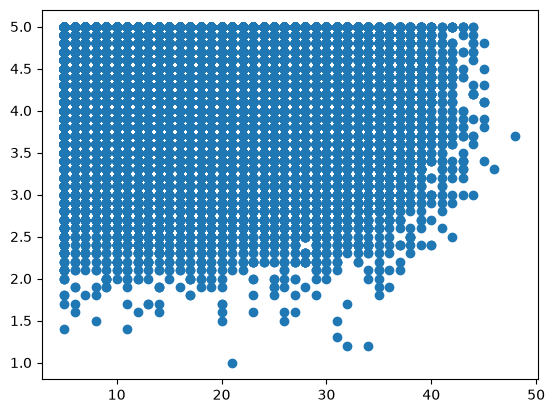

In [114]:
plt.scatter(
    df["consultation_duration_min"],
    df["patient_satisfaction_score"]
)

plt.xlabel("Consultation Duration (Min)")
plt.ylabel("Patient Satisfaction Score")
plt.title("Consultation Duration vs Patient Satisfaction")
plt.show()

In [115]:
#How does doctor experience relate to the fee charged (join with doctors dim)?

In [120]:
df2[['experience_years', 'consultation_fee']].corr()

,experience_years,consultation_fee
experience_years,1.000000,0.278027
consultation_fee,0.278027,1.000000


In [129]:
correlation = df2['experience_years'].corr(df1['actual_fee_charged'])
print(correlation)

-0.05894922987791278
